In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
import scipy as sc 


# TP Optimisation - Descente du gradient
## 1. Étude de la fonction de Rosenbrock

Soit 
$$f(x,y) = (x-1)^2 + 10(x^2-y)^2.$$

1. Montrer que $f$ admet un unique minimum et le déterminer.

In [2]:
def frosenbrock(x,y):
    return (x-1)**2 + 10*(x**2 - y)**2

2. Voici la répresentation de la surface de $f$ sur le pavé $[-2,2]\times[-1,3]$. La fonction $f$ est-elle convexe ?

In [3]:
x = np.arange(-2.0,2.0,0.02)
y = np.arange(-1.0,4.0,0.02)
X, Y = np.meshgrid(x,y)
Z = frosenbrock(X,Y)

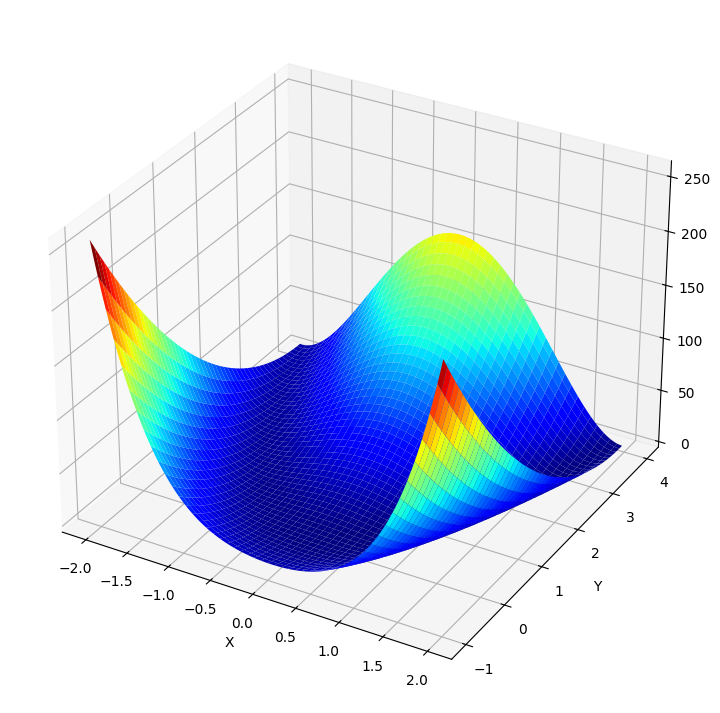

In [4]:

fig = plt.figure(figsize =(14, 9))
ax = plt.axes(projection ='3d')
ax.plot_surface(X, Y, Z, vmin=Z.min() * 2, cmap=cm.jet)
ax.set_xlabel('X')
ax.set_ylabel('Y')
plt.show()


3. Programmer une fonction qui permet d'évaluer le gradient de la fonction $f$.

## Méthode de gradient à pas fixe

On rappelle ci-dessous la définition de l'algorithme de descente de gradient à pas fixe pour minimiser une fonction $f:\mathbb{R}^d\to\mathbb{R}$.


1. Fixer un nombre maximal d'itérations $N$, un seuil d'arrêt $\epsilon$, un pas de descente $\alpha$, et un point initial $x_0$.

2. Tant que le critère d'arrêt n'est pas satisfait :
   1. Calculer la direction de descente :
      
      $$
      d_k = -\nabla f(x_k).
      $$

   2. Construire $x_{k+1}$ par la relation de récurrence :
      
      $$
      x_{k+1} = x_k + \alpha d_k.
      $$

   3. Si le nombre maximal d'itérations est atteint, ou si
      $$
      \|x_{k+1} - x_k\| < \epsilon,
      $$
      arrêter.


1. Programmer la méthode de descente de gradient à pas fixe : écrire une fonction prenant comme arguments le point de départ $x_0$, le nombre maximal d'itérations $N$, le pas de descente $\alpha,$ le seuil d'arrêt $\epsilon$, ainsi qu'une fonction permettant d'évaluer le gradient $\nabla f$.

2.  Appliquer la méthode de descente de gradient à la fonction de Rosenbrock à partir du point $(-1,1)$ pour différentes valeurs de paramètres  $\alpha$, $N$ et $\epsilon$.
 Afficher à chaque fois sur les contours de $f$ la trajectoire des points calculés successivement. Commenter les résultats obtenus pour les différentes valeurs des paramètres. 

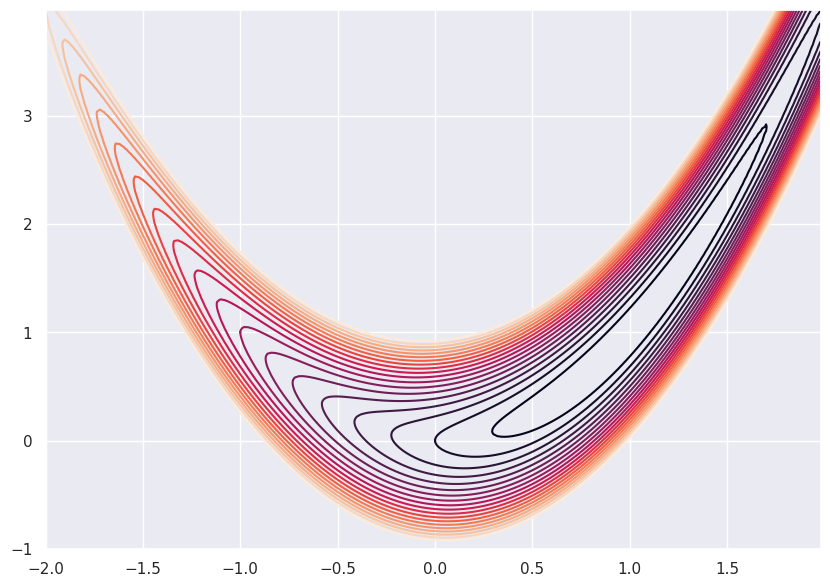

In [5]:
## Pour tracer les contours de f :
sns.set_theme()
fig = plt.figure(figsize=(10,7))
plt.contour(X,Y,Z,np.arange(0.5,10,0.5))

# Huber Loss

## Génération de données

In [6]:
x=np.random.normal(0,1,size=(10,5))
for i in range(1,10):
    new=np.random.normal(i,1,size=(10,5))
    x = np.append(x,new,axis=0)
beta=np.array([[1,2,3,4,5]])
noise_sd=0
n=np.shape(x)[0]
y=np.dot(x[0,],beta[0,])+np.random.normal(0,noise_sd)
for i in range(1,n):
    y=np.append(y,np.dot(x[i,],beta[0,]))+np.random.normal(0,noise_sd)

# Application